In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

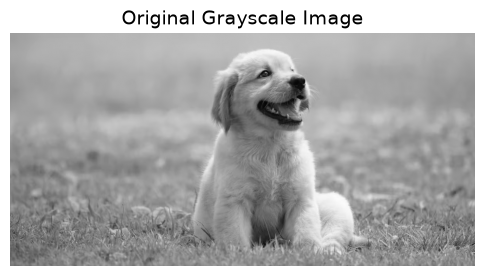

Image Dimensions: (602, 1200)


In [2]:
image = cv2.imread("../Data/Dog.jpg", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(6, 5))
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image", fontsize=14)
plt.axis("off")
plt.show()

print("Image Dimensions:", image.shape)

In [3]:
def compute_otsu_threshold(img: np.ndarray) -> tuple[int, np.ndarray, np.ndarray, np.ndarray]:
    histogram = np.bincount(img.flatten(), minlength=256)
    total_pixels = img.size
    total_sum = np.sum(np.arange(256) * histogram)

    background_weight = 0
    background_sum = 0
    max_variance = 0.0
    threshold_value = 0
    variances = np.zeros(256, dtype=np.float64)

    for t in range(256):
        background_weight += histogram[t]
        if background_weight == 0:
            continue
        foreground_weight = total_pixels - background_weight
        if foreground_weight == 0:
            break
        background_sum += t * histogram[t]

        mean_background = background_sum / background_weight
        mean_foreground = (total_sum - background_sum) / foreground_weight

        variance = float(background_weight) * float(foreground_weight) * ((mean_background - mean_foreground) ** 2)
        variances[t] = variance

        if variance > max_variance:
            max_variance = variance
            threshold_value = t

    thresholded = (img > threshold_value).astype(np.uint8) * 255
    return threshold_value, thresholded, variances, histogram

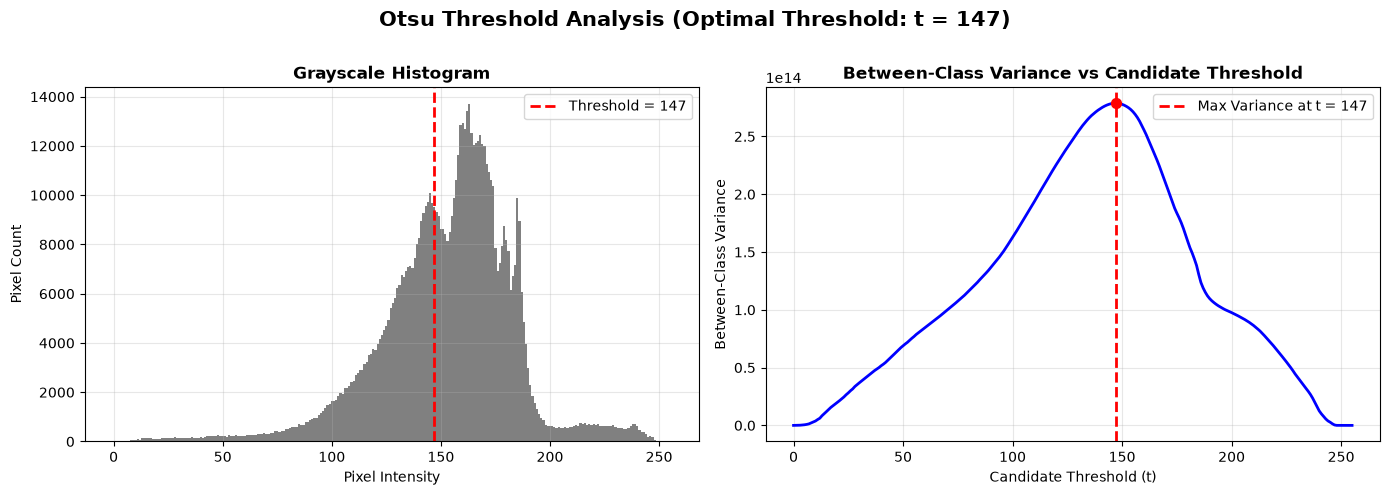

Manual OTSU Threshold Value: 147


In [4]:
threshold_value, manual_result, variances, histogram = compute_otsu_threshold(image)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f"Otsu Threshold Analysis (Optimal Threshold: t = {threshold_value})", fontsize=15, fontweight="bold")

axes[0].bar(range(256), histogram, color="gray", width=1.0)
axes[0].axvline(threshold_value, color="red", linestyle="--", linewidth=2, label=f"Threshold = {threshold_value}")
axes[0].set_title("Grayscale Histogram", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Pixel Intensity")
axes[0].set_ylabel("Pixel Count")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(256), variances, color="blue", linewidth=2)
axes[1].axvline(threshold_value, color="red", linestyle="--", linewidth=2, label=f"Max Variance at t = {threshold_value}")
axes[1].scatter([threshold_value], [variances[threshold_value]], color="red", s=50, zorder=5)
axes[1].set_title("Between-Class Variance vs Candidate Threshold", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Candidate Threshold (t)")
axes[1].set_ylabel("Between-Class Variance")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Manual OTSU Threshold Value:", threshold_value)

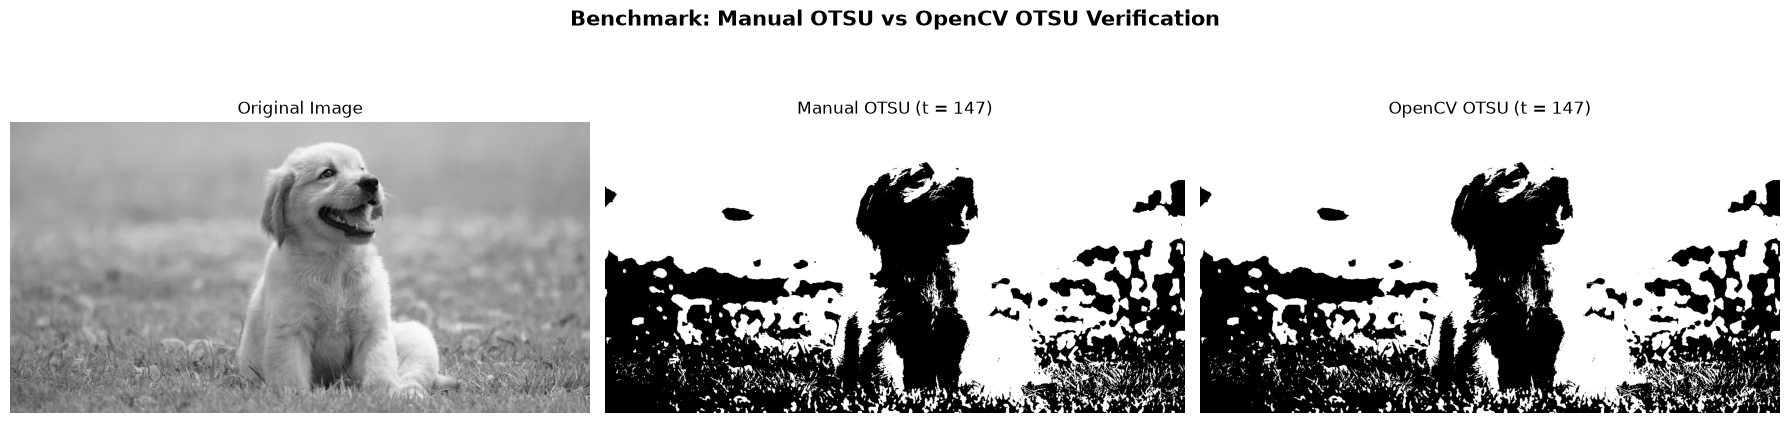

Manual OTSU Threshold Value: 147
OpenCV OTSU Threshold Value: 147.0
Thresholds Match: True
Images Match: True
Mean Absolute Difference: 0.0


In [5]:
cv_threshold, cv_result = cv2.threshold(
    image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

diff_map = np.abs(manual_result.astype(np.int32) - cv_result.astype(np.int32))
mean_abs_diff = np.mean(diff_map)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Benchmark: Manual OTSU vs OpenCV OTSU Verification", fontsize=15, fontweight="bold")

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image", fontsize=12)
axes[0].axis("off")

axes[1].imshow(manual_result, cmap="gray")
axes[1].set_title(f"Manual OTSU (t = {threshold_value})", fontsize=12)
axes[1].axis("off")

axes[2].imshow(cv_result, cmap="gray")
axes[2].set_title(f"OpenCV OTSU (t = {cv_threshold:.0f})", fontsize=12)
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("Manual OTSU Threshold Value:", threshold_value)
print("OpenCV OTSU Threshold Value:", cv_threshold)
print("Thresholds Match:", threshold_value == cv_threshold)
print("Images Match:", np.array_equal(manual_result, cv_result))
print("Mean Absolute Difference:", mean_abs_diff)

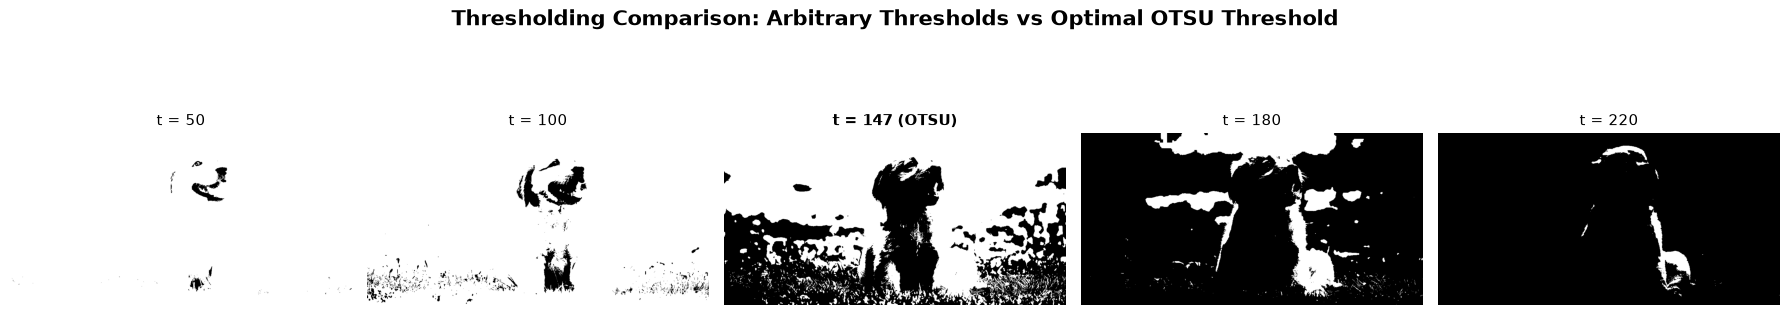

In [6]:
test_thresholds = [50, 100, threshold_value, 180, 220]

fig, axes = plt.subplots(1, len(test_thresholds), figsize=(18, 4))
fig.suptitle("Thresholding Comparison: Arbitrary Thresholds vs Optimal OTSU Threshold", fontsize=15, fontweight="bold")

for idx, t in enumerate(test_thresholds):
    thresh_img = (image > t).astype(np.uint8) * 255
    axes[idx].imshow(thresh_img, cmap="gray")
    title_suffix = " (OTSU)" if t == threshold_value else ""
    axes[idx].set_title(f"t = {t}{title_suffix}", fontsize=11, fontweight="bold" if t == threshold_value else "normal")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()